## 1. Project setup

In [ ]:
# Life Insurance Financial Performance Analytics Using Python
# Dataset: Canadian life insurance regulatory financial data
# Focus: aggregate industry-level financial performance, not individual claims.

## 2. Load the dataset

In [9]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Keep the CSV in the same folder as this notebook.
DATA_PATH = Path(r"C:\Users\ATCHAYA\Desktop\PROJECT\life_insurance_claims_analytics..csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Place the CSV beside this notebook or update DATA_PATH."
    )

# Load the dataset once.
df = pd.read_csv(DATA_PATH)

# Standardize column names.
df_clean = df.rename(columns={
    "Fiscal Year/Année fiscale": "fiscal_year",
    "Fiscal Quarter": "fiscal_quarter",
    "Total Life Insurance Companies/FIs": "entity_group",
    "Industry Group": "industry_group",
    "Data Point Address Label": "measure_label",
    "Measure Value/Valeur de mesure": "measure_value",
    "Id": "data_point_id"
}).copy()

print("Dataset loaded successfully.")
print(f"Rows: {df_clean.shape[0]:,}")
print(f"Columns: {df_clean.shape[1]:,}")
print("\nStandardized columns:")
print(df_clean.columns.tolist())

display(df_clean.head())


Dataset loaded successfully.
Rows: 120,076
Columns: 16

Standardized columns:
['fiscal_year', 'fiscal_quarter', 'Trimestre fiscal', 'data_point_id', 'entity_group', 'Total Sociétés d’assurance-vie/IFFs', 'industry_group', 'Groupe Sectoriel', 'Return/Relevé', 'Return Title', 'Titre du relevé', 'Data Point Address/Adresse de point de donnée', 'measure_label', "Libellé de l'adresse du point de données", "FI Inactive Date/Date d'inactivité IFF", 'measure_value']


,fiscal_year,fiscal_quarter,Trimestre fiscal,data_point_id,entity_group,Total Sociétés d’assurance-vie/IFFs,industry_group,Groupe Sectoriel,Return/Relevé,Return Title,Titre du relevé,Data Point Address/Adresse de point de donnée,measure_label,Libellé de l'adresse du point de données,FI Inactive Date/Date d'inactivité IFF,measure_value
0,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000201001,"LF1: ASSETS: Cash and Cash Equivalents, Curren...","LF1: ACTIF : Encaisse et quasi-espèces, Exerci...",9999-12-31,"881,247.13"
1,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000201003,"LF1: ASSETS: Cash and Cash Equivalents, Prior ...","LF1: ACTIF : Encaisse et quasi-espèces, Exerci...",9999-12-31,"688,886.14"
2,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000202001,"LF1: ASSETS: Accrued Investment Income, Curren...","LF1: ACTIF : Revenu d'investissement couru, Ex...",9999-12-31,"324,644.59"
3,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000202003,"LF1: ASSETS: Accrued Investment Income, Prior ...","LF1: ACTIF : Revenu d'investissement couru, Ex...",9999-12-31,"371,845.45"
4,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000205001,"LF1: ASSETS: Current Tax Assets, Current Perio...","LF1: ACTIF : Actifs d'impôt exigible, Exercice...",9999-12-31,"130,591.81"


## 3. Explore and validate the source data

In [10]:
# Inspect the dataset structure
display(df.info())
display(df.head(3))
display(pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120076 entries, 0 to 120075
Data columns (total 16 columns):
 #   Column                                         Non-Null Count   Dtype  
---  ------                                         --------------   -----  
 0   Fiscal Year/Année fiscale                      120076 non-null  int64  
 1   Fiscal Quarter                                 120076 non-null  object 
 2   Trimestre fiscal                               120076 non-null  object 
 3   Id                                             120076 non-null  int64  
 4   Total Life Insurance Companies/FIs             120076 non-null  object 
 5   Total Sociétés d’assurance-vie/IFFs            120076 non-null  object 
 6   Industry Group                                 120076 non-null  object 
 7   Groupe Sectoriel                               120076 non-null  object 
 8   Return/Relevé                                  120076 non-null  object 
 9   Return Title                         

None

,Fiscal Year/Année fiscale,Fiscal Quarter,Trimestre fiscal,Id,Total Life Insurance Companies/FIs,Total Sociétés d’assurance-vie/IFFs,Industry Group,Groupe Sectoriel,Return/Relevé,Return Title,Titre du relevé,Data Point Address/Adresse de point de donnée,Data Point Address Label,Libellé de l'adresse du point de données,FI Inactive Date/Date d'inactivité IFF,Measure Value/Valeur de mesure
0,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000201001,"LF1: ASSETS: Cash and Cash Equivalents, Curren...","LF1: ACTIF : Encaisse et quasi-espèces, Exerci...",9999-12-31,"881,247.13"
1,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000201003,"LF1: ASSETS: Cash and Cash Equivalents, Prior ...","LF1: ACTIF : Encaisse et quasi-espèces, Exerci...",9999-12-31,"688,886.14"
2,2026,Q3 - 2026,T3 - 2026,1000008,Total Canadian Life Companies,Total sociétés d’assurance-vie canadiennes,Canadian Life Companies,Sociétés d’assurance-vie canadiennes,LF1,LF1 - Life Core Financial Statement Return,LF1 - Vie Relevé des états financiers,P2000202001,"LF1: ASSETS: Accrued Investment Income, Curren...","LF1: ACTIF : Revenu d'investissement couru, Ex...",9999-12-31,"324,644.59"


,data_type,missing_count,missing_percent
Fiscal Year/Année fiscale,int64,0,0.00
Fiscal Quarter,object,0,0.00
Trimestre fiscal,object,0,0.00
Id,int64,0,0.00
Total Life Insurance Companies/FIs,object,0,0.00
Total Sociétés d’assurance-vie/IFFs,object,0,0.00
Industry Group,object,0,0.00
Groupe Sectoriel,object,0,0.00
Return/Relevé,object,0,0.00
Return Title,object,0,0.00


## 4. Initial data-quality checks

In [11]:
# Check duplicates and completely empty rows
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Completely empty rows:", int(df.isna().all(axis=1).sum()))
print("Fiscal years:", sorted(df["Fiscal Year/Année fiscale"].dropna().unique().tolist()))
print("Quarter examples:", df["Fiscal Quarter"].dropna().drop_duplicates().head(8).tolist())

Exact duplicate rows: 0
Completely empty rows: 0
Fiscal years: [2023, 2024, 2025, 2026]
Quarter examples: ['Q3 - 2026', 'Q2 - 2026', 'Q1 - 2026', 'Q4 - 2025', 'Q3 - 2025', 'Q2 - 2025', 'Q1 - 2025', 'Q4 - 2024']


## 5. Clean column names and data types

In [12]:
# Standardize the column names used in the analysis.
# Keep the original dataset columns intact in df; create a clean working copy.
df_clean = df.rename(columns={
    "Fiscal Year/Année fiscale": "fiscal_year",
    "Fiscal Quarter": "fiscal_quarter",
    "Total Life Insurance Companies/FIs": "entity_group",
    "Industry Group": "industry_group",
    "Return/Relevé": "return_code",
    "Data Point Address Label": "measure_label",
    "Measure Value/Valeur de mesure": "measure_value",
}).copy()

df_clean["fiscal_year"] = pd.to_numeric(df_clean["fiscal_year"], errors="coerce")
df_clean["measure_value"] = pd.to_numeric(df_clean["measure_value"], errors="coerce")

display(df_clean[[
    "fiscal_year", "fiscal_quarter", "entity_group",
    "measure_label", "measure_value"
]].head())

,fiscal_year,fiscal_quarter,entity_group,measure_label,measure_value
0,2026,Q3 - 2026,Total Canadian Life Companies,"LF1: ASSETS: Cash and Cash Equivalents, Curren...","881,247.13"
1,2026,Q3 - 2026,Total Canadian Life Companies,"LF1: ASSETS: Cash and Cash Equivalents, Prior ...","688,886.14"
2,2026,Q3 - 2026,Total Canadian Life Companies,"LF1: ASSETS: Accrued Investment Income, Curren...","324,644.59"
3,2026,Q3 - 2026,Total Canadian Life Companies,"LF1: ASSETS: Accrued Investment Income, Prior ...","371,845.45"
4,2026,Q3 - 2026,Total Canadian Life Companies,"LF1: ASSETS: Current Tax Assets, Current Perio...","130,591.81"


## 6. Data-quality summary

In [13]:
# Data-quality checks for the fields used in the analysis
quality_checks = pd.Series({
    "Missing fiscal year": int(df_clean["fiscal_year"].isna().sum()),
    "Missing fiscal quarter": int(df_clean["fiscal_quarter"].isna().sum()),
    "Missing entity group": int(df_clean["entity_group"].isna().sum()),
    "Missing measure label": int(df_clean["measure_label"].isna().sum()),
    "Missing measure value": int(df_clean["measure_value"].isna().sum()),
    "Negative measure values": int((df_clean["measure_value"] < 0).sum()),
})
display(quality_checks.to_frame("count"))

# Negative values are flagged for review, not automatically removed:
# some financial measures can legitimately be negative.

,count
Missing fiscal year,0
Missing fiscal quarter,0
Missing entity group,0
Missing measure label,0
Missing measure value,0
Negative measure values,25027


## 7. Filter the aggregate Canadian life insurance industry

In [14]:
# The aggregate row must be filtered explicitly.
# "Canadian Life Companies" is a broader industry group and includes company-level rows.
aggregate_name = "Total Canadian Life Companies"
industry_df = df_clean.loc[
    df_clean["entity_group"].eq(aggregate_name)
].copy()

print("Aggregate industry rows:", f"{len(industry_df):,}")
print("Entities in filtered data:", industry_df["entity_group"].nunique())
display(industry_df[["fiscal_year", "fiscal_quarter", "measure_label", "measure_value"]].head())

Aggregate industry rows: 6,558
Entities in filtered data: 1


,fiscal_year,fiscal_quarter,measure_label,measure_value
0,2026,Q3 - 2026,"LF1: ASSETS: Cash and Cash Equivalents, Curren...","881,247.13"
1,2026,Q3 - 2026,"LF1: ASSETS: Cash and Cash Equivalents, Prior ...","688,886.14"
2,2026,Q3 - 2026,"LF1: ASSETS: Accrued Investment Income, Curren...","324,644.59"
3,2026,Q3 - 2026,"LF1: ASSETS: Accrued Investment Income, Prior ...","371,845.45"
4,2026,Q3 - 2026,"LF1: ASSETS: Current Tax Assets, Current Perio...","130,591.81"


## 8. Build a chronological fiscal-quarter field

In [15]:
# Create sortable fiscal-quarter fields from labels such as "Q3 - 2026".
industry_df["quarter_number"] = pd.to_numeric(
    industry_df["fiscal_quarter"].astype(str).str.extract(r"Q([1-4])", expand=False),
    errors="coerce"
)
industry_df["quarter_year"] = pd.to_numeric(
    industry_df["fiscal_quarter"].astype(str).str.extract(r"(20\d{2})", expand=False),
    errors="coerce"
)
industry_df["period_sort"] = industry_df["quarter_year"] * 10 + industry_df["quarter_number"]
industry_df["period_label"] = (
    industry_df["quarter_year"].astype("Int64").astype(str)
    + " Q"
    + industry_df["quarter_number"].astype("Int64").astype(str)
)
industry_df = industry_df.dropna(subset=["period_sort"]).sort_values("period_sort")

display(
    industry_df[["fiscal_year", "fiscal_quarter", "period_label", "period_sort"]]
    .drop_duplicates()
    .sort_values("period_sort")
    .tail(12)
)

,fiscal_year,fiscal_quarter,period_label,period_sort
6509,2023,Q4 - 2023,2023 Q4,20234
5882,2024,Q1 - 2024,2024 Q1,20241
5250,2024,Q2 - 2024,2024 Q2,20242
4619,2024,Q3 - 2024,2024 Q3,20243
4278,2024,Q4 - 2024,2024 Q4,20244
3405,2025,Q1 - 2025,2025 Q1,20251
2815,2025,Q2 - 2025,2025 Q2,20252
2207,2025,Q3 - 2025,2025 Q3,20253
1617,2025,Q4 - 2025,2025 Q4,20254
1021,2026,Q1 - 2026,2026 Q1,20261


## 9. Select financial measures

In [16]:
# Select clearly labelled current-period financial measures.
revenue_label = "LF1: STATEMENT OF PROFIT OR LOSS, Total Insurance Revenue, Current Period"
expense_label = "LF1: STATEMENT OF PROFIT OR LOSS, Insurance service expenses, Current Period"
service_result_label = "LF1: STATEMENT OF PROFIT OR LOSS, INSURANCE SERVICE RESULT, Current Period"

selected_labels = [revenue_label, expense_label, service_result_label]
financial_df = industry_df.loc[
    industry_df["measure_label"].isin(selected_labels)
].copy()

# Confirm there is at most one reported record for each period and measure.
duplicates_by_period_measure = financial_df.duplicated(
    subset=["period_sort", "measure_label"], keep=False
)
print("Selected financial records:", len(financial_df))
print("Duplicate period/measure rows:", int(duplicates_by_period_measure.sum()))
display(financial_df[["period_label", "measure_label", "measure_value"]].head(12))

Selected financial records: 45
Duplicate period/measure rows: 0


,period_label,measure_label,measure_value
8398,2023 Q1,"LF1: STATEMENT OF PROFIT OR LOSS, INSURANCE SE...","2,276,286.00"
8392,2023 Q1,"LF1: STATEMENT OF PROFIT OR LOSS, Total Insura...","17,573,645.00"
8394,2023 Q1,"LF1: STATEMENT OF PROFIT OR LOSS, Insurance se...","14,546,233.00"
7755,2023 Q2,"LF1: STATEMENT OF PROFIT OR LOSS, INSURANCE SE...","4,658,068.00"
7749,2023 Q2,"LF1: STATEMENT OF PROFIT OR LOSS, Total Insura...","34,979,032.00"
7751,2023 Q2,"LF1: STATEMENT OF PROFIT OR LOSS, Insurance se...","28,684,621.00"
7115,2023 Q3,"LF1: STATEMENT OF PROFIT OR LOSS, INSURANCE SE...","7,242,551.00"
7109,2023 Q3,"LF1: STATEMENT OF PROFIT OR LOSS, Total Insura...","53,374,023.00"
7111,2023 Q3,"LF1: STATEMENT OF PROFIT OR LOSS, Insurance se...","43,698,826.00"
6471,2023 Q4,"LF1: STATEMENT OF PROFIT OR LOSS, INSURANCE SE...","9,988,547.00"


## 10. Create the quarterly performance table

In [17]:
# Reshape the three selected measures into one row per fiscal quarter.
quarterly_performance = (
    financial_df.pivot_table(
        index=["quarter_year", "quarter_number", "period_sort", "period_label"],
        columns="measure_label",
        values="measure_value",
        aggfunc="first"
    )
    .reset_index()
    .sort_values("period_sort")
    .rename(columns={
        revenue_label: "total_insurance_revenue",
        expense_label: "insurance_service_expenses",
        service_result_label: "reported_insurance_service_result"
    })
)

display(quarterly_performance.tail(12))

measure_label,quarter_year,quarter_number,period_sort,period_label,reported_insurance_service_result,insurance_service_expenses,total_insurance_revenue
3,2023,4,20234,2023 Q4,"9,988,547.00","58,458,473.00","71,763,790.00"
4,2024,1,20241,2024 Q1,"2,711,085.80","16,443,507.60","19,813,781.88"
5,2024,2,20242,2024 Q2,"5,616,333.57","32,694,704.32","39,941,956.87"
6,2024,3,20243,2024 Q3,"8,576,054.21","49,277,344.05","60,383,780.70"
7,2024,4,20244,2024 Q4,"10,974,294.96","67,062,463.73","81,276,031.96"
8,2025,1,20251,2025 Q1,"2,885,090.44","17,593,034.26","21,579,160.10"
9,2025,2,20252,2025 Q2,"5,779,113.56","35,373,439.79","43,146,313.79"
10,2025,3,20253,2025 Q3,"9,134,306.81","52,968,825.90","65,301,379.58"
11,2025,4,20254,2025 Q4,"12,394,529.26","71,261,790.37","87,748,873.64"
12,2026,1,20261,2026 Q1,"3,223,753.69","18,400,630.11","22,672,326.07"


## 11. Descriptive statistics

In [18]:
# Summary statistics for the selected financial measures
measure_columns = [
    "total_insurance_revenue",
    "insurance_service_expenses",
    "reported_insurance_service_result"
]
display(quarterly_performance[measure_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
measure_label,,,,,,,,
total_insurance_revenue,15.00,"44,579,530.81","25,182,364.55","3,306,115.10","22,125,743.09","43,146,313.79","62,842,580.14","87,748,873.64"
insurance_service_expenses,15.00,"36,422,251.85","20,515,564.61","2,807,794.85","17,996,832.19","35,373,439.79","51,123,084.97","71,261,790.37"
reported_insurance_service_result,15.00,"6,164,132.75","3,535,274.75","398,380.46","3,054,422.06","5,779,113.56","8,855,180.51","12,394,529.26"


## 12. Quarterly trend visualization

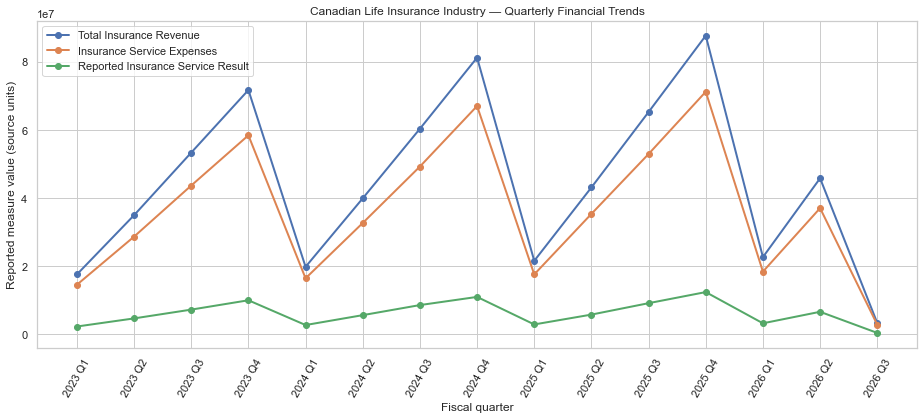

In [19]:
# Plot the quarterly trends. Values are shown as reported in the source dataset.
fig, ax = plt.subplots(figsize=(13, 6))
for column in measure_columns:
    if column in quarterly_performance.columns:
        ax.plot(
            quarterly_performance["period_label"],
            quarterly_performance[column],
            marker="o",
            linewidth=2,
            label=column.replace("_", " ").title()
        )
ax.set_title("Canadian Life Insurance Industry — Quarterly Financial Trends")
ax.set_xlabel("Fiscal quarter")
ax.set_ylabel("Reported measure value (source units)")
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.tight_layout()
plt.show()

## 13. Q4 year-end comparison

In [20]:
# Compare Q4 reported values by fiscal year.
# Q4 is used as the year-end observation; do not sum Q1–Q4 because these
# regulatory statements may report period-to-date values.
q4_performance = quarterly_performance.loc[
    quarterly_performance["quarter_number"].eq(4)
].copy().sort_values("quarter_year")

display(q4_performance[[
    "quarter_year",
    "total_insurance_revenue",
    "insurance_service_expenses",
    "reported_insurance_service_result"
]])

measure_label,quarter_year,total_insurance_revenue,insurance_service_expenses,reported_insurance_service_result
3,2023,"71,763,790.00","58,458,473.00","9,988,547.00"
7,2024,"81,276,031.96","67,062,463.73","10,974,294.96"
11,2025,"87,748,873.64","71,261,790.37","12,394,529.26"


In [27]:
# Calculate total revenue growth from Q4 2023 to Q4 2025

revenue_2023 = q4_performance.loc[
    q4_performance["quarter_year"] == 2023,
    "total_insurance_revenue"
].iloc[0]

revenue_2025 = q4_performance.loc[
    q4_performance["quarter_year"] == 2025,
    "total_insurance_revenue"
].iloc[0]

revenue_growth_pct = (
    (revenue_2025 - revenue_2023) / revenue_2023
) * 100

print(f"Q4 2023 Revenue: ${revenue_2023 / 1_000_000:.2f} million")
print(f"Q4 2025 Revenue: ${revenue_2025 / 1_000_000:.2f} million")
print(f"Total Revenue Growth: {revenue_growth_pct:.2f}%")

Q4 2023 Revenue: $71.76 million
Q4 2025 Revenue: $87.75 million
Total Revenue Growth: 22.27%


In [28]:
# Calculate total insurance service expense growth from Q4 2023 to Q4 2025

expenses_2023 = q4_performance.loc[
    q4_performance["quarter_year"] == 2023,
    "insurance_service_expenses"
].iloc[0]

expenses_2025 = q4_performance.loc[
    q4_performance["quarter_year"] == 2025,
    "insurance_service_expenses"
].iloc[0]

expense_growth_pct = (
    (expenses_2025 - expenses_2023) / expenses_2023
) * 100

print(f"Q4 2023 Insurance Service Expenses: ${expenses_2023 / 1_000_000:.2f} million")
print(f"Q4 2025 Insurance Service Expenses: ${expenses_2025 / 1_000_000:.2f} million")
print(f"Total Expense Growth: {expense_growth_pct:.2f}%")

Q4 2023 Insurance Service Expenses: $58.46 million
Q4 2025 Insurance Service Expenses: $71.26 million
Total Expense Growth: 21.90%


In [29]:
# Calculate reported insurance service result growth from Q4 2023 to Q4 2025

result_2023 = q4_performance.loc[
    q4_performance["quarter_year"] == 2023,
    "reported_insurance_service_result"
].iloc[0]

result_2025 = q4_performance.loc[
    q4_performance["quarter_year"] == 2025,
    "reported_insurance_service_result"
].iloc[0]

result_growth_pct = (
    (result_2025 - result_2023) / result_2023
) * 100

print(f"Q4 2023 Reported Insurance Service Result: ${result_2023 / 1_000_000:.2f} million")
print(f"Q4 2025 Reported Insurance Service Result: ${result_2025 / 1_000_000:.2f} million")
print(f"Total Growth: {result_growth_pct:.2f}%")

Q4 2023 Reported Insurance Service Result: $9.99 million
Q4 2025 Reported Insurance Service Result: $12.39 million
Total Growth: 24.09%


In [30]:
# Calculate reported insurance service result-to-revenue ratio

q4_performance["service_result_to_revenue_pct"] = (
    q4_performance["reported_insurance_service_result"]
    / q4_performance["total_insurance_revenue"]
) * 100

display(
    q4_performance[
        ["quarter_year", "service_result_to_revenue_pct"]
    ].round(2)
)

measure_label,quarter_year,service_result_to_revenue_pct
3,2023,13.92
7,2024,13.50
11,2025,14.13


## 14. Q4 comparison chart

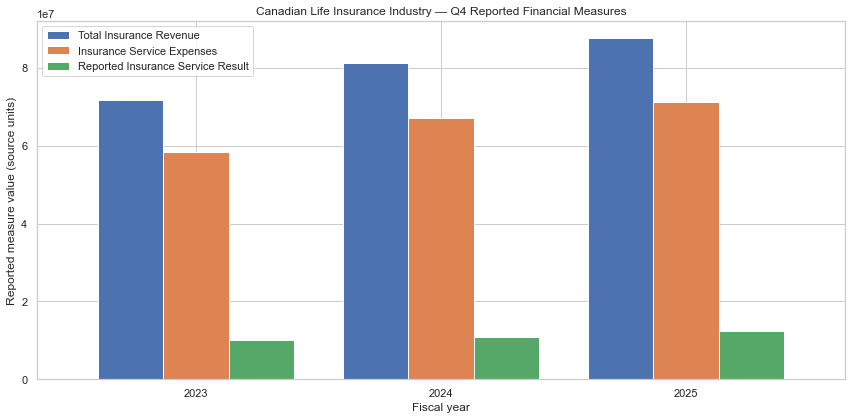

In [21]:
# Plot Q4 year-end observations for the three measures
plot_cols = [
    "total_insurance_revenue",
    "insurance_service_expenses",
    "reported_insurance_service_result"
]
available_plot_cols = [col for col in plot_cols if col in q4_performance.columns]

ax = q4_performance.set_index("quarter_year")[available_plot_cols].plot(
    kind="bar", figsize=(12, 6), width=0.8
)
ax.set_title("Canadian Life Insurance Industry — Q4 Reported Financial Measures")
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Reported measure value (source units)")
ax.legend([col.replace("_", " ").title() for col in available_plot_cols])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 15. Year-over-year changes

In [22]:
# Year-over-year change in Q4 reported revenue and expenses.
growth = q4_performance[[
    "quarter_year", "total_insurance_revenue", "insurance_service_expenses"
]].copy()

growth["revenue_yoy_change_pct"] = growth["total_insurance_revenue"].pct_change() * 100
growth["expenses_yoy_change_pct"] = growth["insurance_service_expenses"].pct_change() * 100

display(growth.round(2))

measure_label,quarter_year,total_insurance_revenue,insurance_service_expenses,revenue_yoy_change_pct,expenses_yoy_change_pct
3,2023,"71,763,790.00","58,458,473.00",NaN,NaN
7,2024,"81,276,031.96","67,062,463.73",13.25,14.72
11,2025,"87,748,873.64","71,261,790.37",7.96,6.26


## 16. Growth visualization

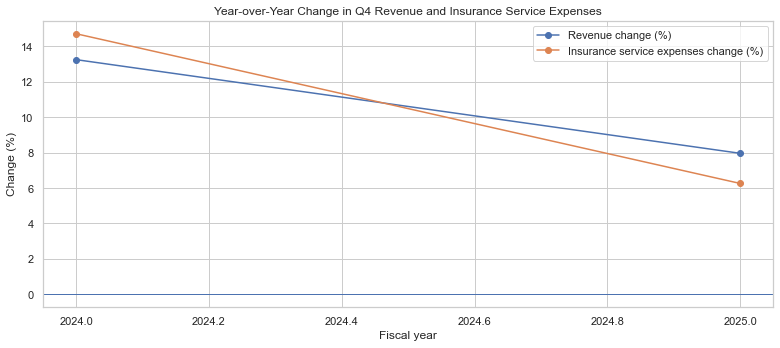

In [23]:
# Visualize year-over-year percentage changes
growth_plot = growth.set_index("quarter_year")[
    ["revenue_yoy_change_pct", "expenses_yoy_change_pct"]
].dropna(how="all")

ax = growth_plot.plot(kind="line", marker="o", figsize=(11, 5))
ax.axhline(0, linewidth=1)
ax.set_title("Year-over-Year Change in Q4 Revenue and Insurance Service Expenses")
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Change (%)")
ax.legend(["Revenue change (%)", "Insurance service expenses change (%)"])
plt.tight_layout()
plt.show()

## 18. Statistical analysis: correlation

This section examines linear relationships among the three reported financial measures. It calculates Pearson correlations for reported levels and quarter-over-quarter percentage changes. Correlation does **not** establish causation, and correlations between trending financial series can be misleading. Interpret the results cautiously because the dataset contains relatively few quarterly observations.

Quarterly observations used: 15


measure_label,total_insurance_revenue,insurance_service_expenses,reported_insurance_service_result
measure_label,,,
total_insurance_revenue,1.00,1.00,1.00
insurance_service_expenses,1.00,1.00,1.00
reported_insurance_service_result,1.00,1.00,1.00


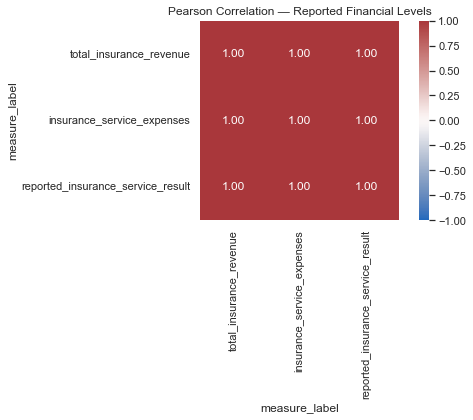

Quarter-over-quarter change observations used: 14


measure_label,total_insurance_revenue,insurance_service_expenses,reported_insurance_service_result
measure_label,,,
total_insurance_revenue,1.00,1.00,1.00
insurance_service_expenses,1.00,1.00,1.00
reported_insurance_service_result,1.00,1.00,1.00


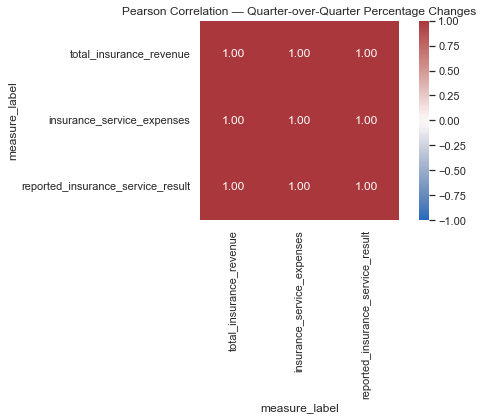

In [24]:
measure_columns = [
    "total_insurance_revenue",
    "insurance_service_expenses",
    "reported_insurance_service_result"
]

correlation_data = quarterly_performance[measure_columns].dropna()
print(f"Quarterly observations used: {len(correlation_data)}")

level_corr = correlation_data.corr(method="pearson")
display(level_corr.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(level_corr, annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson Correlation — Reported Financial Levels")
plt.tight_layout()
plt.show()

# Percentage changes can reduce (but do not eliminate) shared-trend effects.
change_data = (
    quarterly_performance[measure_columns]
    .pct_change(fill_method=None)
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)
print(f"Quarter-over-quarter change observations used: {len(change_data)}")

if len(change_data) >= 3:
    change_corr = change_data.corr(method="pearson")
    display(change_corr.round(3))

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(change_corr, annot=True, fmt=".2f", cmap="vlag",
                center=0, vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title("Pearson Correlation — Quarter-over-Quarter Percentage Changes")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough observations to calculate a useful change-correlation matrix.")

## 19. Exploratory forecasting: next four quarters

A simple linear-trend model provides a transparent baseline. The last three observed quarters are held out to estimate error; the model is then refit using all available observations to project the next four quarters.

**Limitations:** there are relatively few quarterly observations, so this is an exploratory baseline—not a reliable actuarial or business forecast. It does not model seasonality, regulatory changes, acquisitions, inflation, or other external drivers. Confirm the source's period definitions before using projections for decisions. Forecasts are point estimates, not confidence intervals.

Validation results (last 3 quarters held out):


,measure,validation_quarters,MAE,MAPE_percent
0,total_insurance_revenue,3,"50,116,197.41",837.28
1,insurance_service_expenses,3,"40,870,730.53",805.57
2,reported_insurance_service_result,3,"6,947,281.27",960.10


Exploratory linear-trend projections (not confidence intervals):


,quarter_year,quarter_number,period_label,total_insurance_revenue,insurance_service_expenses,reported_insurance_service_result
0,2026,4,2026 Q4,"44,000,912.25","35,738,456.17","6,220,190.85"
1,2027,1,2027 Q1,"43,928,584.93","35,652,981.71","6,227,198.11"
2,2027,2,2027 Q2,"43,856,257.61","35,567,507.25","6,234,205.37"
3,2027,3,2027 Q3,"43,783,930.28","35,482,032.80","6,241,212.63"


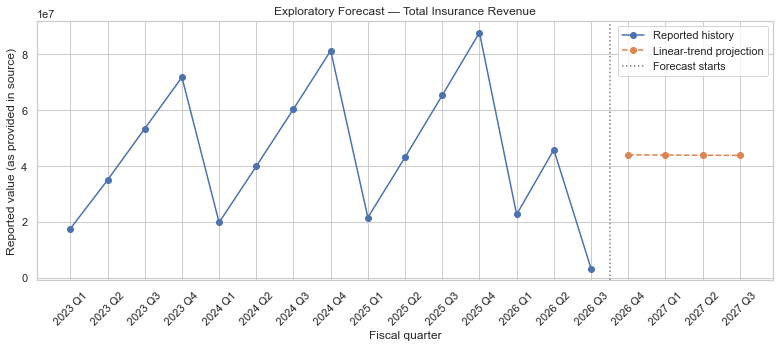

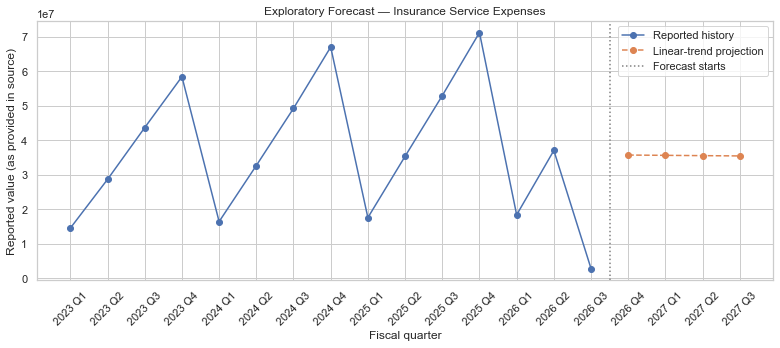

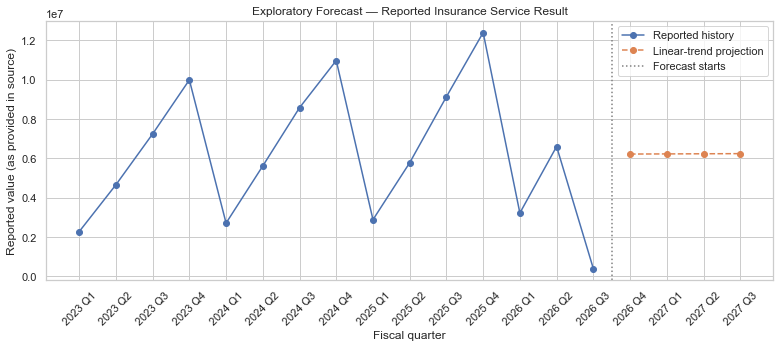

In [25]:
forecast_measures = [
    "total_insurance_revenue",
    "insurance_service_expenses",
    "reported_insurance_service_result"
]

forecast_source = (
    quarterly_performance[
        ["quarter_year", "quarter_number", "period_sort", "period_label"] + forecast_measures
    ]
    .sort_values("period_sort")
    .drop_duplicates(subset=["period_sort"])
    .reset_index(drop=True)
)

HOLDOUT_QUARTERS = 3
MIN_TRAINING_QUARTERS = 6

if len(forecast_source) < MIN_TRAINING_QUARTERS + HOLDOUT_QUARTERS:
    print("Forecast skipped: not enough observations for the train/validation split.")
else:
    train = forecast_source.iloc[:-HOLDOUT_QUARTERS].copy()
    test = forecast_source.iloc[-HOLDOUT_QUARTERS:].copy()
    validation_rows = []

    for measure in forecast_measures:
        train_values = train[measure].astype(float).to_numpy()
        test_values = test[measure].astype(float).to_numpy()
        train_x = np.arange(len(train), dtype=float)
        test_x = np.arange(len(train), len(train) + len(test), dtype=float)

        slope, intercept = np.polyfit(train_x, train_values, 1)
        predictions = slope * test_x + intercept
        mae = float(np.mean(np.abs(test_values - predictions)))
        nonzero = test_values != 0
        mape = (
            float(np.mean(np.abs((test_values[nonzero] - predictions[nonzero])
                                 / test_values[nonzero])) * 100)
            if nonzero.any() else np.nan
        )
        validation_rows.append({
            "measure": measure,
            "validation_quarters": len(test),
            "MAE": mae,
            "MAPE_percent": mape
        })

    print("Validation results (last 3 quarters held out):")
    display(pd.DataFrame(validation_rows).round(2))

    # Generate labels for the four quarters following the latest observed quarter.
    year = int(forecast_source.iloc[-1]["quarter_year"])
    quarter = int(forecast_source.iloc[-1]["quarter_number"])
    future_periods = []
    for _ in range(4):
        quarter += 1
        if quarter > 4:
            quarter = 1
            year += 1
        future_periods.append({
            "quarter_year": year,
            "quarter_number": quarter,
            "period_label": f"{year} Q{quarter}"
        })

    future_x = np.arange(len(forecast_source), len(forecast_source) + 4, dtype=float)
    forecast_table = pd.DataFrame(future_periods)
    all_x = np.arange(len(forecast_source), dtype=float)

    for measure in forecast_measures:
        values = forecast_source[measure].astype(float).to_numpy()
        slope, intercept = np.polyfit(all_x, values, 1)
        forecast_table[measure] = slope * future_x + intercept

    print("Exploratory linear-trend projections (not confidence intervals):")
    display(forecast_table.round(2))

    for measure in forecast_measures:
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.plot(forecast_source["period_label"], forecast_source[measure],
                marker="o", label="Reported history")
        ax.plot(forecast_table["period_label"], forecast_table[measure],
                marker="o", linestyle="--", label="Linear-trend projection")
        ax.axvline(len(forecast_source) - 0.5, color="gray", linestyle=":",
                   label="Forecast starts")
        ax.set_title(f"Exploratory Forecast — {measure.replace('_', ' ').title()}")
        ax.set_xlabel("Fiscal quarter")
        ax.set_ylabel("Reported value (as provided in source)")
        ax.tick_params(axis="x", rotation=45)
        ax.legend()
        plt.tight_layout()
        plt.show()

## 17. Latest-quarter snapshot

In [26]:
# Latest available quarter in the aggregate dataset
if not quarterly_performance.empty:
    latest = quarterly_performance.sort_values("period_sort").iloc[-1]
    print("Latest period:", latest["period_label"])
    for column in measure_columns:
        if column in quarterly_performance.columns:
            print(f"{column.replace('_', ' ').title()}: {latest[column]:,.2f}")
else:
    print("No rows matched the selected financial measures.")

Latest period: 2026 Q3
Total Insurance Revenue: 3,306,115.10
Insurance Service Expenses: 2,807,794.85
Reported Insurance Service Result: 398,380.46


## 18. Optional exports

In [ ]:
# Export analysis-ready tables (optional)
# Uncomment these lines if you want CSV outputs saved beside the notebook.
# quarterly_performance.to_csv("quarterly_industry_financial_performance.csv", index=False)
# q4_performance.to_csv("q4_industry_financial_performance.csv", index=False)